## 02 — Skill Discovery


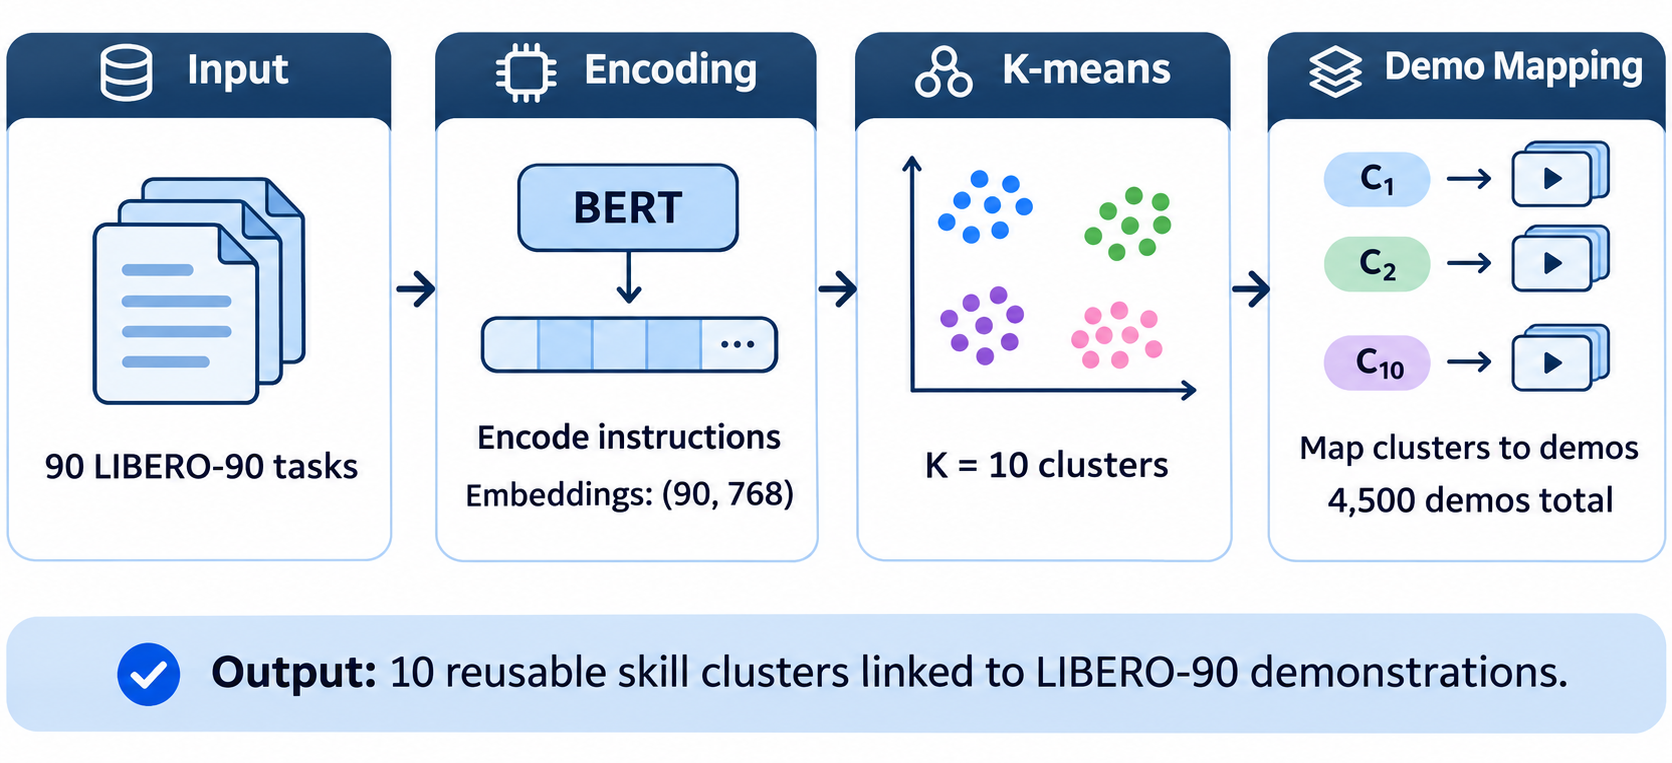


HSR discovers reusable skills by encoding natural-language task instructions and clustering them according to semantic similarity.

In this notebook, we will use pretrained BERT embeddings and K-means clustering (\(K=10\)) to identify skill groups within LIBERO-90.

Reference: HSR Paper, Section IV-A.

In [1]:
%env HF_HOME=/blue/uf-eig/FILLMEIN/cache/
%env TORCH_HOME=/blue/uf-eig/FILLMEIN/cache/
%env HF_HUB_CACHE=/blue/uf-eig/FILLMEIN/cache/huggingface/hub
%env HF_XET_CACHE=/blue/uf-eig/FILLMEIN/cache/huggingface/xet
%env DATA_ROOT=/blue/uf-eig/FILLMEIN/HSR-Replication/datasets

env: HF_HOME=/blue/uf-eig/FILLMEIN/cache/
env: TORCH_HOME=/blue/uf-eig/FILLMEIN/cache/
env: HF_HUB_CACHE=/blue/uf-eig/FILLMEIN/cache/huggingface/hub
env: HF_XET_CACHE=/blue/uf-eig/FILLMEIN/cache/huggingface/xet
env: DATA_ROOT=/blue/uf-eig/FILLMEIN/HSR-Replication/datasets


In [2]:
import os
import sys
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt


PROJECT_ROOT = Path("/blue/uf-eig/FILLMEIN/HSR-Replication")
sys.path.insert(0, str(PROJECT_ROOT))
from src.data import get_task_instructions
from src.skills import encode_instructions, cluster_skills
from sklearn.metrics.pairwise import cosine_similarity


In [3]:
# Load the dataset index from Blue storage
index_path = Path(os.environ["DATA_ROOT"]).parent / "dataset_index.csv"
index = pd.read_csv(index_path)

# Extract unique LIBERO-90 task instructions
tasks = get_task_instructions(index)

print("Number of tasks:", len(tasks))
display(tasks.head(90))

Number of tasks: 90


,task,instruction
0,KITCHEN_SCENE10_close_the_top_drawer_of_the_ca...,close the top drawer of the cabinet and put th...
50,KITCHEN_SCENE10_close_the_top_drawer_of_the_ca...,close the top drawer of the cabinet
100,KITCHEN_SCENE10_put_the_black_bowl_in_the_top_...,put the black bowl in the top drawer of the ca...
150,KITCHEN_SCENE10_put_the_butter_at_the_back_in_...,put the butter at the back in the top drawer o...
200,KITCHEN_SCENE10_put_the_butter_at_the_front_in...,put the butter at the front in the top drawer ...
...,...,...
4250,STUDY_SCENE3_pick_up_the_white_mug_and_place_i...,pick up the white mug and place it to the righ...
4300,STUDY_SCENE4_pick_up_the_book_in_the_middle_an...,pick up the book in the middle and place it on...
4350,STUDY_SCENE4_pick_up_the_book_on_the_left_and_...,pick up the book on the left and place it on t...
4400,STUDY_SCENE4_pick_up_the_book_on_the_right_and...,pick up the book on the right and place it on ...


## Encoding Our Instructions

We use our `encode_instructions()` function to convert the 90 unique LIBERO-90 task instructions into numerical embeddings using pretrained BERT.

Each instruction is represented by a **768-dimensional vector**, obtained by averaging its token embeddings using masked mean pooling.

The resulting embedding matrix has shape **(90, 768)**, where each row represents a task instruction and each column represents an embedding feature.

These embeddings will be used for semantic similarity analysis and K-means clustering to discover reusable skill groups.

In [4]:
instructions = tasks["instruction"].tolist()


# Find in src/skills.py
embeddings = encode_instructions(instructions)

print("Embeddings shape:", embeddings.shape)

/blue/uf-eig/FILLMEIN/.conda/envs/IForgotVLA/lib/python3.10/site-packages/huggingface_hub/file_download.py:945: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(


Embeddings shape: (90, 768)


## Analyzing Instruction Embeddings
We have encoded 90 LIBERO-90 task instructions into 768-dimensional BERT embeddings.

Before clustering, we will examine the embeddings and calculate cosine similarity to determine whether semantically related instructions have similar representations.

This helps us evaluate whether the embeddings are suitable for discovering reusable skill groups.

In [5]:

# Inspect embedding dimensions and values
print("Shape:", embeddings.shape)
# print("First embedding:", embeddings[0][:10])
# print("Contains NaN:", np.isnan(embeddings).any())



# Compare every instruction with every other instruction
similarity = cosine_similarity(embeddings)
# This gives us a matrix where similarity[i, j] measures the similarity between instructions i and j.
# print("Similarity matrix:", similarity.shape)

# Select the first instruction
i = 0

# Find the 5 most similar instructions, excluding itself
neighbors = np.argsort(similarity[i])[::-1]
neighbors = [j for j in neighbors if j != i][:5]

print("Original:", instructions[i])

for j in neighbors:
    print(f"{similarity[i, j]:.3f} - {instructions[j]}")
    

Shape: (90, 768)
Original: close the top drawer of the cabinet and put the black bowl on top of it
0.957 - open the top drawer of the cabinet and put the bowl in it
0.944 - put the black bowl on top of the cabinet
0.944 - put the black bowl on top of the cabinet
0.944 - put the black bowl on top of the cabinet
0.937 - put the black bowl in the top drawer of the cabinet


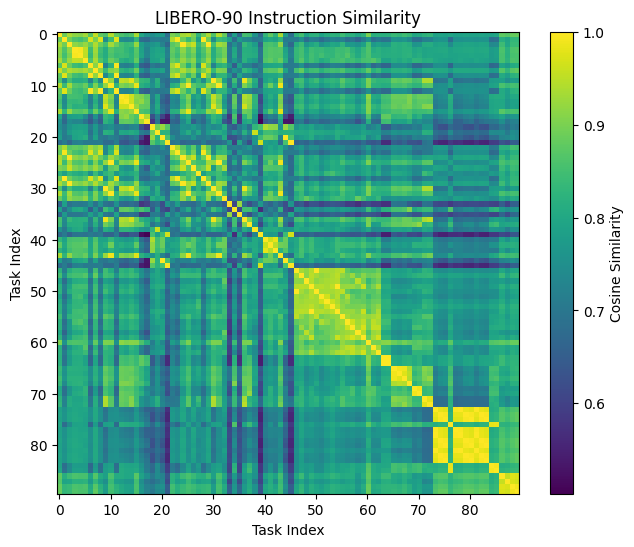

In [6]:

# Visualize pairwise similarities
plt.figure(figsize=(8, 6))
plt.imshow(similarity)
plt.colorbar(label="Cosine Similarity")
plt.xlabel("Task Index")
plt.ylabel("Task Index")
plt.title("LIBERO-90 Instruction Similarity")
plt.show()

### Embedding Analysis — Observations

The cosine similarity matrix reveals visible groups of semantically related LIBERO-90 instructions.

- Similar manipulation tasks generally have higher cosine similarity.
- Similarity scores vary across instructions, indicating meaningful differences in their representations.
- Several clusters of high similarity are visible, suggesting potential groups of reusable skills.

These observations motivate applying **K-means clustering (K=10)** to discover skill groups, as described in HSR.

In [ ]:
# Assign each instruction to one of 10 skill clusters
tasks = tasks.copy()
tasks["cluster"] = cluster_skills(embeddings)

# Inspect cluster sizes
print(tasks.groupby("cluster").size())


# Display task instructions belonging to each cluster
for cluster, group in tasks.groupby("cluster"):
    print(f"\nCluster {cluster} ({len(group)} tasks)")

    for instruction in group["instruction"]:
        print("-", instruction)

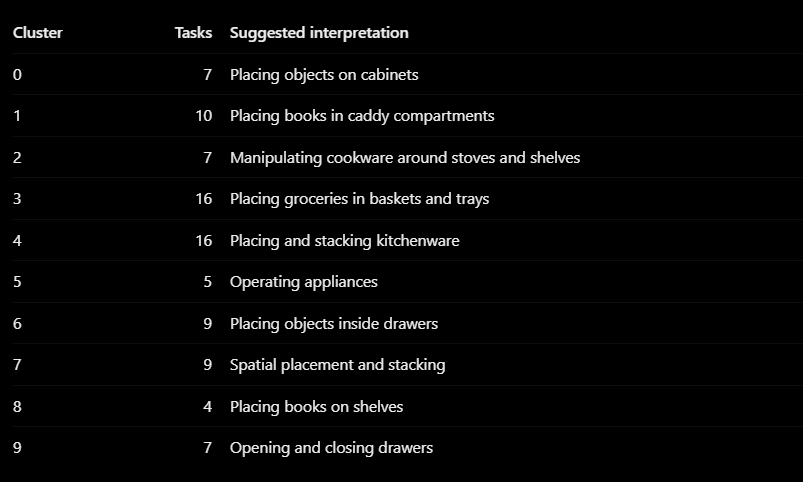

### K-Means Clustering — Observations

K-means assigned the 90 LIBERO-90 tasks into 10 clusters with varying sizes (4–16 tasks).

The clusters show meaningful semantic structure, grouping tasks involving similar objects, destinations, and manipulation operations. However, some clusters represent specific task contexts rather than general-purpose skills.

These clusters will serve as the initial skill groups for HSR. Their reliability will later be estimated using held-out behavior-cloning losses, following Section IV-A of the paper.

In [9]:
# Select LIBERO-90 demonstrations
prior_index = index[index["suite"] == "libero_90"].copy()

# Merge cluster labels into the demonstration index:
# - Select only the task and cluster columns
# - on="task": Match rows using their task name
# - how="left": Keep all demonstrations, even if a cluster is missing
# - validate="many_to_one": Many demos can share a task, but each task has one cluster
prior_index = prior_index.merge(
    tasks[["task", "cluster"]],
    on="task",
    how="left",
    validate="many_to_one"
)

# Verify all demonstrations have cluster assignments
print("Missing clusters:", prior_index["cluster"].isna().sum())
print("\nDemonstrations per cluster:")
print(prior_index.groupby("cluster").size())

Missing clusters: 0

Demonstrations per cluster:
cluster
0    350
1    500
2    350
3    800
4    800
5    250
6    450
7    450
8    200
9    350
dtype: int64


In [ ]:
# Assign descriptive names to the discovered skill clusters
skill_names = {
    0: "Cabinet Surface Placement",
    1: "Caddy Compartment Placement",
    2: "Cookware Placement",
    3: "Grocery Container Placement",
    4: "Kitchenware Placement & Stacking",
    5: "Appliance Operation",
    6: "Drawer Object Placement",
    7: "Spatial Object Placement",
    8: "Shelf Object Placement",
    9: "Drawer Opening & Closing"
}

# Add skill names to our demonstration index
prior_index["skill_name"] = prior_index["cluster"].map(skill_names)

display(prior_index.head())


# Save cluster assignments to Blue storage
prior_index.to_csv(
    dataset_root.parent / "skill_clusters.csv",
    index=False
)

print("Skill discovery complete!")

## Conclusion

We implemented HSR's initial skill discovery using pretrained BERT embeddings and K-means clustering ((K=10)).

The 90 LIBERO-90 tasks were grouped into 10 semantically related skill clusters. We then associated each cluster with its corresponding expert demonstrations.

These skill groups will support subsequent task decomposition, skill-confidence estimation, and demonstration retrieval.